### 1. Импорты

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch
import numpy as np

import json
import platform
import random

import torchvision
from torch import nn

# Определяем корень проекта diplom_project
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    if (PROJECT_ROOT.parent / "src").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent
    else:
        raise FileNotFoundError(
            "Не удалось найти папку src. "
            "Открой notebook внутри проекта diplom_project."
        )

# Добавляем корень проекта в путь Python
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import CLASS_NAMES, load_fashion_mnist, create_train_validation_split, calculate_train_mean_std, create_normalized_transform

from src.model import FashionCNN, count_trainable_parameters

print("Корень проекта:", PROJECT_ROOT)
print("Классы:", CLASS_NAMES)

Корень проекта: d:\Учеба\diplom_project
Классы: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### 2. Загрузка датасета

In [2]:
full_train_dataset, test_dataset = load_fashion_mnist()

print("Размер обучающей выборки:", len(full_train_dataset))
print("Размер тестовой выборки:", len(test_dataset))

Размер обучающей выборки: 60000
Размер тестовой выборки: 10000


### 3. Проверка одного изображения

In [3]:
image, label = full_train_dataset[0]

label = int(label)

print("Тип изображения:", type(image))
print("Размер изображения:", image.shape)
print("Тип данных:", image.dtype)
print("Минимальное значение:", image.min().item())
print("Максимальное значение:", image.max().item())
print("Числовая метка:", label)
print("Название класса:", CLASS_NAMES[label])

assert image.shape == (1, 28, 28)
assert 0 <= label < 10
assert image.min() >= 0
assert image.max() <= 1

print("Проверка изображения пройдена")

Тип изображения: <class 'torch.Tensor'>
Размер изображения: torch.Size([1, 28, 28])
Тип данных: torch.float32
Минимальное значение: 0.0
Максимальное значение: 1.0
Числовая метка: 9
Название класса: Ankle boot
Проверка изображения пройдена


### 4. Проверка количества классов

In [4]:
print("Классы из датасета:")
print(full_train_dataset.classes)

print()
print("Наш список классов:")
print(CLASS_NAMES)

assert len(full_train_dataset.classes) == 10
assert full_train_dataset.classes == CLASS_NAMES

unique_labels = torch.unique(full_train_dataset.targets).tolist()

print("Уникальные метки:", unique_labels)

assert unique_labels == list(range(10))

Классы из датасета:
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Наш список классов:
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Уникальные метки: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


### 5. Количество изображений каждого класса

In [5]:
train_labels = full_train_dataset.targets
test_labels = test_dataset.targets

train_counts = torch.bincount(
    train_labels,
    minlength=len(CLASS_NAMES),
)

test_counts = torch.bincount(
    test_labels,
    minlength=len(CLASS_NAMES),
)

print("Количество изображений в train:")
for class_id, count in enumerate(train_counts):
    print(f"{class_id}: {CLASS_NAMES[class_id]} — {int(count)}")

print()
print("Количество изображений в test:")
for class_id, count in enumerate(test_counts):
    print(f"{class_id}: {CLASS_NAMES[class_id]} — {int(count)}")

assert train_counts.sum().item() == 60000
assert test_counts.sum().item() == 10000
assert torch.all(train_counts == 6000)
assert torch.all(test_counts == 1000)

print("Распределение классов проверено")

Количество изображений в train:
0: T-shirt/top — 6000
1: Trouser — 6000
2: Pullover — 6000
3: Dress — 6000
4: Coat — 6000
5: Sandal — 6000
6: Shirt — 6000
7: Sneaker — 6000
8: Bag — 6000
9: Ankle boot — 6000

Количество изображений в test:
0: T-shirt/top — 1000
1: Trouser — 1000
2: Pullover — 1000
3: Dress — 1000
4: Coat — 1000
5: Sandal — 1000
6: Shirt — 1000
7: Sneaker — 1000
8: Bag — 1000
9: Ankle boot — 1000
Распределение классов проверено


### 6. График распределения классов

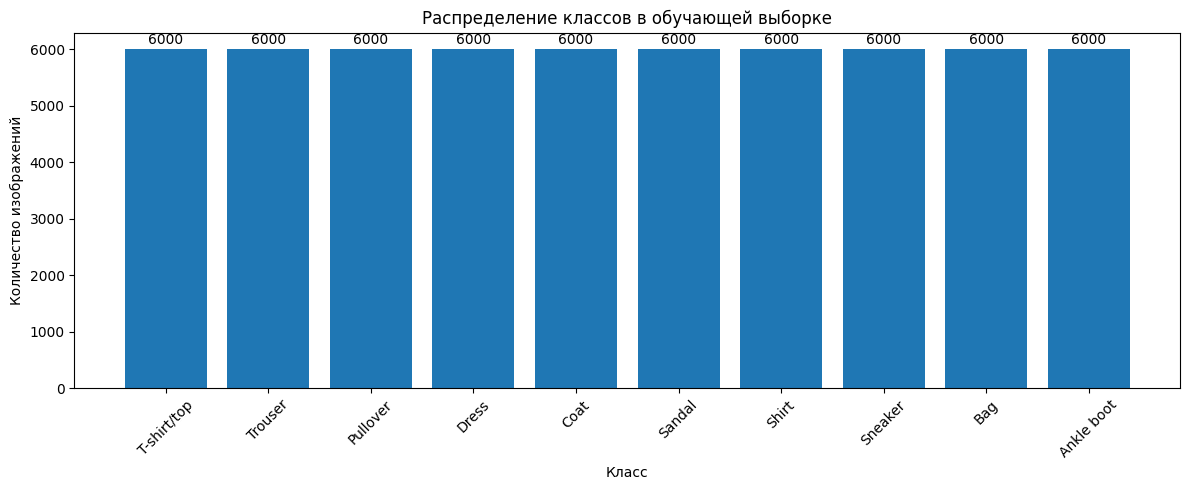

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(CLASS_NAMES, train_counts.numpy())

ax.set_title("Распределение классов в обучающей выборке")
ax.set_xlabel("Класс")
ax.set_ylabel("Количество изображений")
ax.tick_params(axis="x", rotation=45)

for bar, count in zip(bars, train_counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        str(int(count)),
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

### 7. Сетка первых 16 изображений

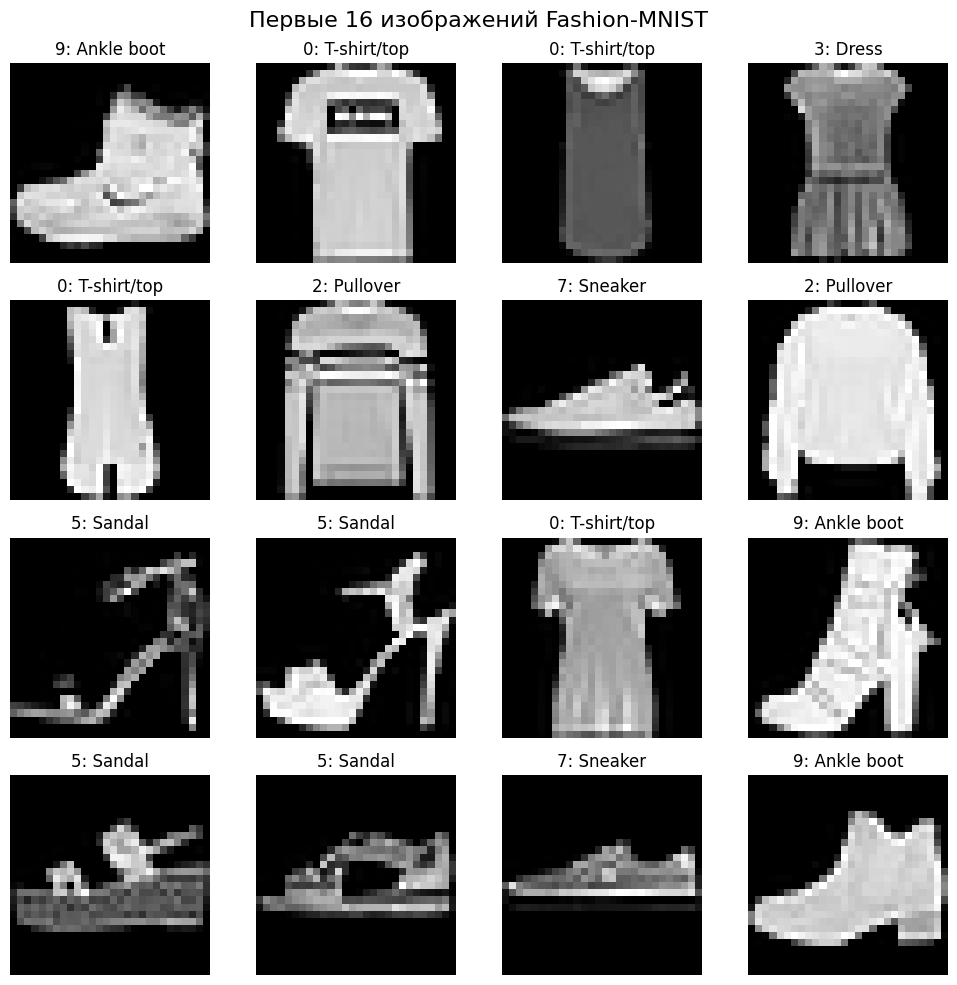

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for index, ax in enumerate(axes.ravel()):
    image, label = full_train_dataset[index]
    label = int(label)

    ax.imshow(image.squeeze().numpy(), cmap="gray")
    ax.set_title(f"{label}: {CLASS_NAMES[label]}")
    ax.axis("off")

fig.suptitle("Первые 16 изображений Fashion-MNIST", fontsize=16)
plt.tight_layout()
plt.show()

### 8. Случайные изображения

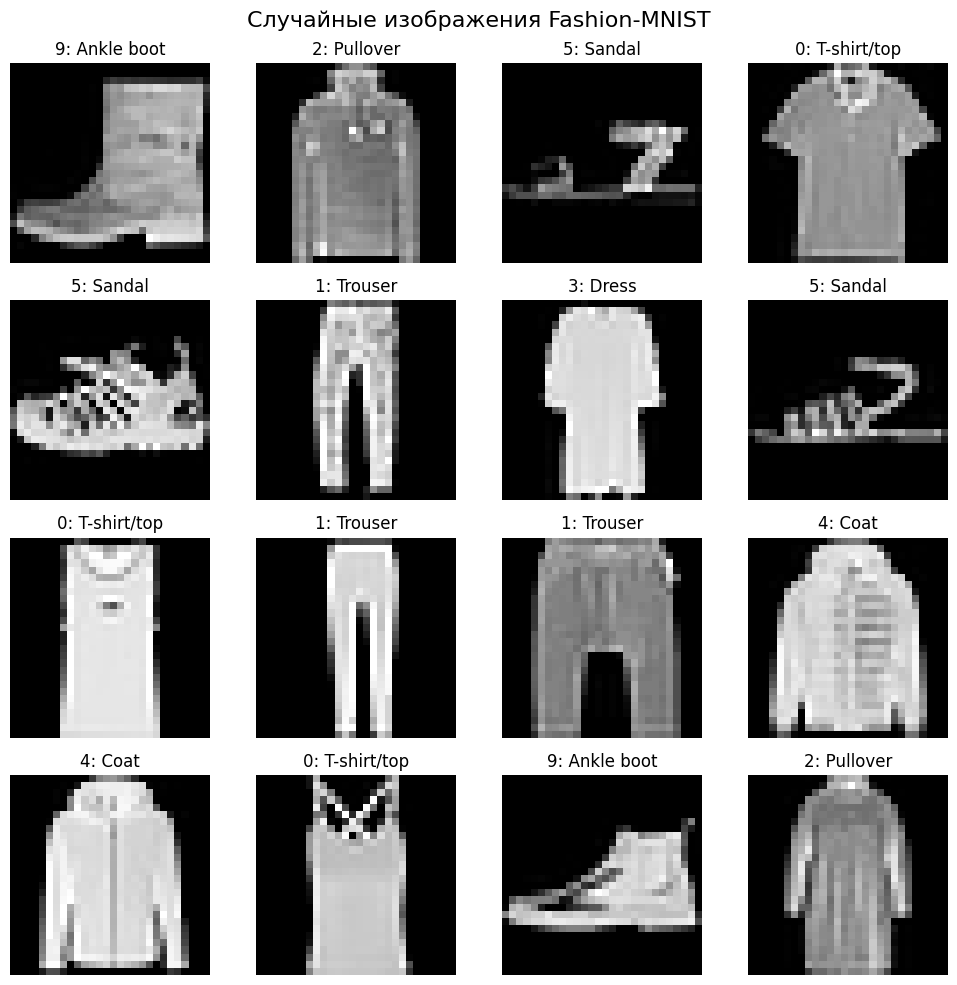

In [8]:
generator = torch.Generator()
generator.manual_seed(42)

random_indices = torch.randperm(
    len(full_train_dataset),
    generator=generator,
)[:16].tolist()

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for ax, index in zip(axes.ravel(), random_indices):
    image, label = full_train_dataset[index]
    label = int(label)

    ax.imshow(image.squeeze().numpy(), cmap="gray")
    ax.set_title(f"{label}: {CLASS_NAMES[label]}")
    ax.axis("off")

fig.suptitle("Случайные изображения Fashion-MNIST", fontsize=16)
plt.tight_layout()
plt.show()

In [9]:
print("Проверка этапа 3 завершена")
print(f"Train: {len(full_train_dataset)} изображений")
print(f"Test: {len(test_dataset)} изображений")
print(f"Размер одного изображения: {full_train_dataset[0][0].shape}")
print(f"Количество классов: {len(CLASS_NAMES)}")

Проверка этапа 3 завершена
Train: 60000 изображений
Test: 10000 изображений
Размер одного изображения: torch.Size([1, 28, 28])
Количество классов: 10


### 9. Разделение на train и validation 

In [10]:
train_dataset, validation_dataset, train_indices, validation_indices = (
    create_train_validation_split(
        full_train_dataset,
        validation_fraction=0.10,
        seed=42,
    )
)

print("Размер train:", len(train_dataset))
print("Размер validation:", len(validation_dataset))
print("Размер test:", len(test_dataset))

Используется сохранённое разбиение.
Размер train: 54000
Размер validation: 6000
Размер test: 10000


In [11]:
## Проверка, что индексы не пересекаются
intersection = np.intersect1d(
    train_indices,
    validation_indices,
)

union = np.union1d(
    train_indices,
    validation_indices,
)

print("Количество общих индексов:", len(intersection))
print("Количество уникальных индексов:", len(union))

assert len(intersection) == 0
assert len(union) == len(full_train_dataset)

print("Train и validation не пересекаются.")

Количество общих индексов: 0
Количество уникальных индексов: 60000
Train и validation не пересекаются.


In [12]:
## Проверка распределения классов
full_targets = full_train_dataset.targets.cpu().numpy()

train_class_counts = np.bincount(
    full_targets[train_indices],
    minlength=10,
)

validation_class_counts = np.bincount(
    full_targets[validation_indices],
    minlength=10,
)

test_targets = test_dataset.targets.cpu().numpy()

test_class_counts = np.bincount(
    test_targets,
    minlength=10,
)

for class_id, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_id}: {class_name:12} | "
        f"train={train_class_counts[class_id]:4} | "
        f"validation={validation_class_counts[class_id]:4} | "
        f"test={test_class_counts[class_id]:4}"
    )

assert train_class_counts.sum() == 54000
assert validation_class_counts.sum() == 6000
assert test_class_counts.sum() == 10000

0: T-shirt/top  | train=5400 | validation= 600 | test=1000
1: Trouser      | train=5400 | validation= 600 | test=1000
2: Pullover     | train=5400 | validation= 600 | test=1000
3: Dress        | train=5400 | validation= 600 | test=1000
4: Coat         | train=5400 | validation= 600 | test=1000
5: Sandal       | train=5400 | validation= 600 | test=1000
6: Shirt        | train=5400 | validation= 600 | test=1000
7: Sneaker      | train=5400 | validation= 600 | test=1000
8: Bag          | train=5400 | validation= 600 | test=1000
9: Ankle boot   | train=5400 | validation= 600 | test=1000


### 10. Нормализация

In [13]:
mean, std = calculate_train_mean_std(
    full_train_dataset=full_train_dataset,
    train_indices=train_indices,
)

print("Среднее значение train:", mean)
print("Стандартное отклонение train:", std)

Среднее значение train: 0.28620901279348543
Стандартное отклонение train: 0.3531597507360165


In [14]:
normalized_transform = create_normalized_transform(
    mean=mean,
    std=std,
)

full_train_dataset.transform = normalized_transform
test_dataset.transform = normalized_transform

In [15]:
train_image, train_label = train_dataset[0]
validation_image, validation_label = validation_dataset[0]
test_image, test_label = test_dataset[0]

print("Размер train image:", train_image.shape)
print("Размер validation image:", validation_image.shape)
print("Размер test image:", test_image.shape)

print()
print("Train image:")
print("min:", train_image.min().item())
print("max:", train_image.max().item())
print("mean:", train_image.mean().item())
print("std:", train_image.std().item())

Размер train image: torch.Size([1, 28, 28])
Размер validation image: torch.Size([1, 28, 28])
Размер test image: torch.Size([1, 28, 28])

Train image:
min: -0.8104236721992493
max: 2.021156072616577
mean: 0.2695055902004242
std: 1.1310476064682007


In [16]:
from torch.utils.data import DataLoader

train_loader_for_check = DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=False,
)

normalized_sum = 0.0
normalized_squared_sum = 0.0
normalized_count = 0

for images, labels in train_loader_for_check:
    normalized_sum += images.sum().item()
    normalized_squared_sum += (images * images).sum().item()
    normalized_count += images.numel()

normalized_mean = normalized_sum / normalized_count

normalized_variance = (
    normalized_squared_sum / normalized_count
    - normalized_mean**2
)

normalized_std = normalized_variance**0.5

print("Среднее после нормализации:", normalized_mean)
print("Стандартное отклонение после нормализации:", normalized_std)

Среднее после нормализации: -3.947908916170635e-08
Стандартное отклонение после нормализации: 0.9999999970474293


In [17]:
import json

config_path = (
    PROJECT_ROOT
    / "configs"
    / "fashion_mnist_baseline.json"
)

if config_path.exists():
    config = json.loads(
        config_path.read_text(encoding="utf-8")
    )
else:
    config = {}

config["normalization"] = {
    "mean": mean,
    "std": std,
    "calculated_from": "train split only",
    "train_size": len(train_indices),
}

config_path.write_text(
    json.dumps(
        config,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print("Значения нормализации сохранены в:", config_path)

Значения нормализации сохранены в: d:\Учеба\diplom_project\configs\fashion_mnist_baseline.json


### 11. CNN

In [18]:
#Создание модели
model = FashionCNN()

print(model)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [19]:
#Подсчёт параметров
parameter_count = count_trainable_parameters(model)

print("Количество обучаемых параметров:", parameter_count)

Количество обучаемых параметров: 105962


In [20]:
#Проверка формы выхода
batch_size = 4

dummy_images = torch.zeros(
    batch_size,
    1,
    28,
    28,
)

logits = model(dummy_images)

print("Размер входа:", dummy_images.shape)
print("Размер выхода:", logits.shape)

assert dummy_images.shape == (4, 1, 28, 28)
assert logits.shape == (4, 10)
assert parameter_count == 105_962

print("Проверка архитектуры пройдена")

Размер входа: torch.Size([4, 1, 28, 28])
Размер выхода: torch.Size([4, 10])
Проверка архитектуры пройдена


In [21]:
#Проверка с реальным изображением
image, label = train_dataset[0]

print("Размер одного изображения:", image.shape)
print("Метка:", label)

image_batch = image.unsqueeze(0)

print("Размер после добавления batch:", image_batch.shape)

with torch.no_grad():
    logits = model(image_batch)

print("Размер logits:", logits.shape)
print("Logits:", logits)

Размер одного изображения: torch.Size([1, 28, 28])
Метка: 9
Размер после добавления batch: torch.Size([1, 1, 28, 28])
Размер logits: torch.Size([1, 10])
Logits: tensor([[-0.1480,  0.1524, -0.0378, -0.4633,  0.3957,  0.4394,  0.1601,  0.0848,
          0.3782,  0.0706]])


In [22]:
#Получение предварительного предсказания
predicted_class = logits.argmax(dim=1).item()

print("Предсказанный класс:", predicted_class)
print("Настоящий класс:", int(label))

Предсказанный класс: 5
Настоящий класс: 9


### 12. Задание параметров обучения

In [23]:
#Фиксированный SEED
SEED = 42


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Повышает воспроизводимость результатов на GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

print("Seed:", SEED)

Seed: 42


In [24]:
#Выбор устройства
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Устройство:", device)

Устройство: cpu


In [25]:
#Параметры обучения
training_config = {
    "seed": 42,
    "batch_size": 128,
    "epochs": 15,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "dropout": 0.3,
    "loss": "CrossEntropyLoss",
    "device": str(device),
}

In [26]:
#Создание модели, функции ошибки и оптимизатора
model = FashionCNN(
    dropout=training_config["dropout"]
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=training_config["learning_rate"],
    weight_decay=training_config["weight_decay"],
)

In [27]:
#Сохранение параметров в конфигурацию
config_path = (
    PROJECT_ROOT
    / "configs"
    / "fashion_mnist_baseline.json"
)

if config_path.exists():
    config = json.loads(
        config_path.read_text(encoding="utf-8")
    )
else:
    config = {}

config["training"] = training_config

config["runtime"] = {
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "device": str(device),
    "trainable_parameters": sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    ),
}

config["dataset_sizes"] = {
    "train": len(train_dataset),
    "validation": len(validation_dataset),
    "test": len(test_dataset),
}

config.setdefault("results", {
    "best_epoch": None,
    "best_validation_accuracy": None,
    "test_accuracy": None,
})

config_path.write_text(
    json.dumps(
        config,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("Конфигурация сохранена в:")
print(config_path)

Конфигурация сохранена в:
d:\Учеба\diplom_project\configs\fashion_mnist_baseline.json


### 13. Реализация обучения

In [28]:
from torch.utils.data import DataLoader


train_loader = DataLoader(
    train_dataset,
    batch_size=training_config["batch_size"],
    shuffle=True,
    num_workers=0,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)

print("Количество train batches:", len(train_loader))
print(
    "Количество validation batches:",
    len(validation_loader),
)

Количество train batches: 422
Количество validation batches: 47


In [29]:
from src.train import fit


model = FashionCNN(
    dropout=training_config["dropout"]
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=training_config["learning_rate"],
    weight_decay=training_config["weight_decay"],
)

In [30]:
checkpoint_path = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "checkpoints"
    / "best_model.pt"
)

history_path = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "history.json"
)

In [31]:
normalization_config = {
    "mean": float(mean),
    "std": float(std),
    "calculated_from": "train split only",
}

In [32]:
architecture_config = {
    "name": "FashionCNN",
    "input_shape": [1, 28, 28],
    "num_classes": 10,
    "dropout": float(
        training_config["dropout"]
    ),
    "layers": [
        {
            "type": "Conv2d",
            "in_channels": 1,
            "out_channels": 16,
            "kernel_size": 3,
            "padding": 1,
        },
        {
            "type": "BatchNorm2d",
            "num_features": 16,
        },
        {
            "type": "ReLU",
        },
        {
            "type": "MaxPool2d",
            "kernel_size": 2,
        },
        {
            "type": "Conv2d",
            "in_channels": 16,
            "out_channels": 32,
            "kernel_size": 3,
            "padding": 1,
        },
        {
            "type": "BatchNorm2d",
            "num_features": 32,
        },
        {
            "type": "ReLU",
        },
        {
            "type": "MaxPool2d",
            "kernel_size": 2,
        },
        {
            "type": "Flatten",
        },
        {
            "type": "Linear",
            "in_features": 32 * 7 * 7,
            "out_features": 64,
        },
        {
            "type": "ReLU",
        },
        {
            "type": "Dropout",
            "probability": 0.3,
        },
        {
            "type": "Linear",
            "in_features": 64,
            "out_features": 10,
        },
    ],
}

In [33]:
checkpoint_metadata = {
    "seed": int(training_config["seed"]),
    "normalization": normalization_config,
    "architecture": architecture_config,
    "training": training_config,
    "dataset_sizes": {
        "train": len(train_dataset),
        "validation": len(validation_dataset),
        "test": len(test_dataset),
    },
}

In [34]:
history = fit(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=training_config["epochs"],
    checkpoint_path=checkpoint_path,
    history_path=history_path,
    checkpoint_metadata=checkpoint_metadata,
)

Epoch 01/15 | train loss: 0.4934 | train accuracy: 0.8236 | validation loss: 0.3027 | validation accuracy: 0.8888
Epoch 02/15 | train loss: 0.3287 | train accuracy: 0.8826 | validation loss: 0.2508 | validation accuracy: 0.9060
Epoch 03/15 | train loss: 0.2899 | train accuracy: 0.8958 | validation loss: 0.2544 | validation accuracy: 0.9000
Epoch 04/15 | train loss: 0.2683 | train accuracy: 0.9010 | validation loss: 0.2280 | validation accuracy: 0.9160
Epoch 05/15 | train loss: 0.2465 | train accuracy: 0.9098 | validation loss: 0.2317 | validation accuracy: 0.9113
Epoch 06/15 | train loss: 0.2337 | train accuracy: 0.9132 | validation loss: 0.2227 | validation accuracy: 0.9183
Epoch 07/15 | train loss: 0.2264 | train accuracy: 0.9171 | validation loss: 0.2158 | validation accuracy: 0.9205
Epoch 08/15 | train loss: 0.2120 | train accuracy: 0.9225 | validation loss: 0.2225 | validation accuracy: 0.9152
Epoch 09/15 | train loss: 0.2022 | train accuracy: 0.9254 | validation loss: 0.2330 | va

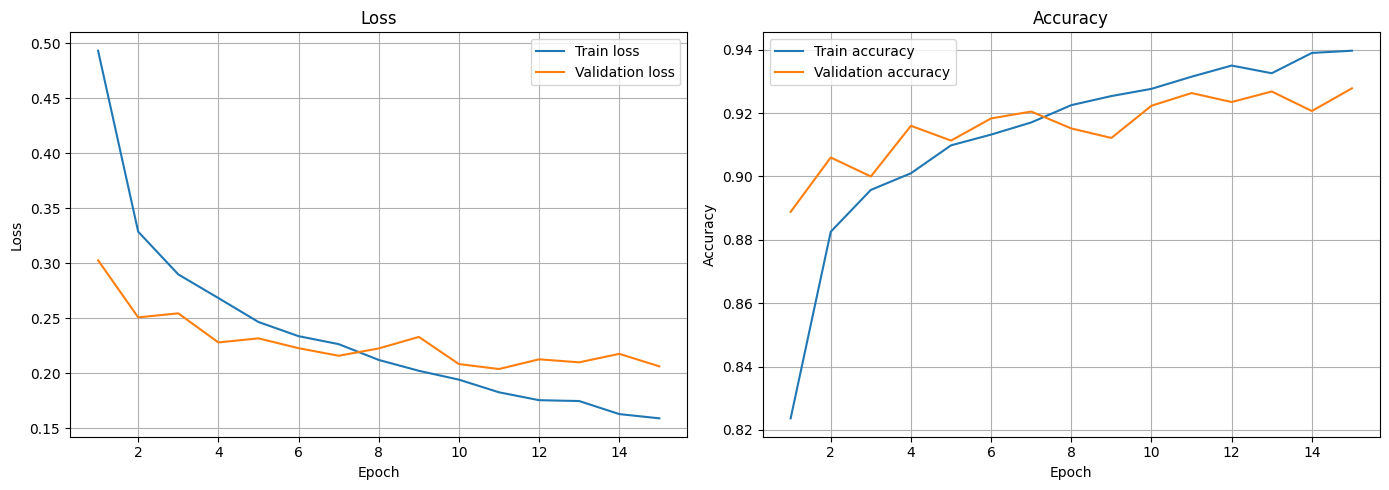

In [35]:
import matplotlib.pyplot as plt


epochs = history["epoch"]

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
)

# График ошибки
axes[0].plot(
    epochs,
    history["train_loss"],
    label="Train loss",
)

axes[0].plot(
    epochs,
    history["validation_loss"],
    label="Validation loss",
)

axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()


# График accuracy
axes[1].plot(
    epochs,
    history["train_accuracy"],
    label="Train accuracy",
)

axes[1].plot(
    epochs,
    history["validation_accuracy"],
    label="Validation accuracy",
)

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

In [36]:
best_index = history["validation_accuracy"].index(
    max(history["validation_accuracy"])
)

best_epoch = history["epoch"][best_index]
best_validation_accuracy = (
    history["validation_accuracy"][best_index]
)

print("Лучшая эпоха:", best_epoch)
print(
    "Лучшая validation accuracy:",
    best_validation_accuracy,
)
print(
    "В процентах:",
    best_validation_accuracy * 100,
)

Лучшая эпоха: 15
Лучшая validation accuracy: 0.9278333333333333
В процентах: 92.78333333333333


In [37]:
#Проверка содержимого checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
)
print(checkpoint.keys())

dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'validation_loss', 'validation_accuracy', 'history', 'seed', 'normalization', 'architecture', 'training', 'dataset_sizes'])


### 14. Расчёт метрик на test

In [38]:
from torch.utils.data import DataLoader

#Создание test_loader
test_loader = DataLoader(
    test_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)

In [39]:
#Загрузка общей модели
import torch
from src.model import FashionCNN


checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
)

saved_training_config = checkpoint.get(
    "training",
    training_config,
)

best_model = FashionCNN(
    dropout=saved_training_config["dropout"]
).to(device)

best_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_model.eval()

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [40]:
print("Эпоха модели:", checkpoint["epoch"])
print(
    "Validation accuracy:",
    checkpoint["validation_accuracy"],
)

Эпоха модели: 15
Validation accuracy: 0.9278333333333333


In [41]:
#Получение предсказаний на test
import numpy as np


all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        logits = best_model(images)

        predictions = logits.argmax(dim=1)

        all_labels.append(labels.cpu())
        all_predictions.append(
            predictions.cpu()
        )

y_true = torch.cat(all_labels).numpy()
y_pred = torch.cat(all_predictions).numpy()

print("Количество тестовых изображений:", len(y_true))

Количество тестовых изображений: 10000


In [42]:
#Расчёт общей accuracy и Macro-F1
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score


overall_accuracy = accuracy_score(
    y_true,
    y_pred,
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

print(
    "Test accuracy:",
    overall_accuracy,
)

print(
    "Test accuracy (%):",
    overall_accuracy * 100,
)

print(
    "Macro-F1:",
    macro_f1,
)

Test accuracy: 0.9162
Test accuracy (%): 91.62
Macro-F1: 0.9156375132180606


In [43]:
#Расчёт accuracy для каждого класса
from sklearn.metrics import confusion_matrix


class_ids = np.arange(len(CLASS_NAMES))

confusion = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids,
)

per_class_metrics = []

for class_id, class_name in enumerate(CLASS_NAMES):
    total_samples = confusion[class_id].sum()
    correct_predictions = confusion[
        class_id,
        class_id,
    ]

    class_accuracy = (
        correct_predictions / total_samples
    )

    per_class_metrics.append(
        {
            "class_id": int(class_id),
            "class_name": class_name,
            "total_samples": int(total_samples),
            "correct_predictions": int(
                correct_predictions
            ),
            "accuracy": float(class_accuracy),
        }
    )

for item in per_class_metrics:
    print(
        f'{item["class_id"]} '
        f'{item["class_name"]}: '
        f'{item["accuracy"]:.4f}'
    )

0 T-shirt/top: 0.8610
1 Trouser: 0.9850
2 Pullover: 0.8880
3 Dress: 0.9270
4 Coat: 0.8840
5 Sandal: 0.9740
6 Shirt: 0.7210
7 Sneaker: 0.9750
8 Bag: 0.9830
9 Ankle boot: 0.9640


In [44]:
#Сохранение общей метрики в JSON
import json


metrics_dir = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "metrics"
)

metrics_dir.mkdir(
    parents=True,
    exist_ok=True,
)

test_metrics = {
    "checkpoint_epoch": int(
        checkpoint["epoch"]
    ),
    "checkpoint_validation_accuracy": float(
        checkpoint["validation_accuracy"]
    ),
    "test_size": int(len(y_true)),
    "accuracy": float(overall_accuracy),
    "macro_f1": float(macro_f1),
}

test_metrics_path = (
    metrics_dir
    / "test_metrics.json"
)

test_metrics_path.write_text(
    json.dumps(
        test_metrics,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "Общие метрики сохранены в:",
    test_metrics_path,
)

Общие метрики сохранены в: d:\Учеба\diplom_project\experiments\fashion_mnist\baseline\metrics\test_metrics.json


In [45]:
#Сохранение accuracy по классам в CSV
import csv


per_class_metrics_path = (
    metrics_dir
    / "per_class_metrics.csv"
)

with per_class_metrics_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:

    fieldnames = [
        "class_id",
        "class_name",
        "total_samples",
        "correct_predictions",
        "accuracy",
    ]

    writer = csv.DictWriter(
        csv_file,
        fieldnames=fieldnames,
    )

    writer.writeheader()
    writer.writerows(per_class_metrics)

print(
    "Метрики по классам сохранены в:",
    per_class_metrics_path,
)

Метрики по классам сохранены в: d:\Учеба\diplom_project\experiments\fashion_mnist\baseline\metrics\per_class_metrics.csv


### 15. Построение матрицы ошибок

In [46]:
from sklearn.metrics import confusion_matrix


class_ids = np.arange(len(CLASS_NAMES))

confusion = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids,
)

print("Размер матрицы:", confusion.shape)
print(confusion)

Размер матрицы: (10, 10)
[[861   0  16  27   4   1  86   0   5   0]
 [  0 985   0   9   1   0   1   0   4   0]
 [ 13   1 888   8  48   0  40   0   2   0]
 [  9   8  11 927  17   0  28   0   0   0]
 [  2   0  43  24 884   0  46   0   1   0]
 [  0   0   0   0   0 974   0  22   1   3]
 [100   4  62  41  63   0 721   0   9   0]
 [  0   0   0   0   0   4   0 975   0  21]
 [  3   2   0   3   1   1   4   3 983   0]
 [  0   0   1   0   0   5   0  30   0 964]]


In [47]:
#Сохранение матрицы в CSV
import csv


metrics_dir = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "metrics"
)

metrics_dir.mkdir(
    parents=True,
    exist_ok=True,
)

confusion_csv_path = (
    metrics_dir
    / "confusion_matrix.csv"
)

with confusion_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:

    writer = csv.writer(csv_file)

    writer.writerow(
        ["true_class"] + list(CLASS_NAMES)
    )

    for class_name, row in zip(
        CLASS_NAMES,
        confusion,
    ):
        writer.writerow(
            [class_name] + row.tolist()
        )

print(
    "CSV сохранён в:",
    confusion_csv_path,
)

CSV сохранён в: d:\Учеба\diplom_project\experiments\fashion_mnist\baseline\metrics\confusion_matrix.csv


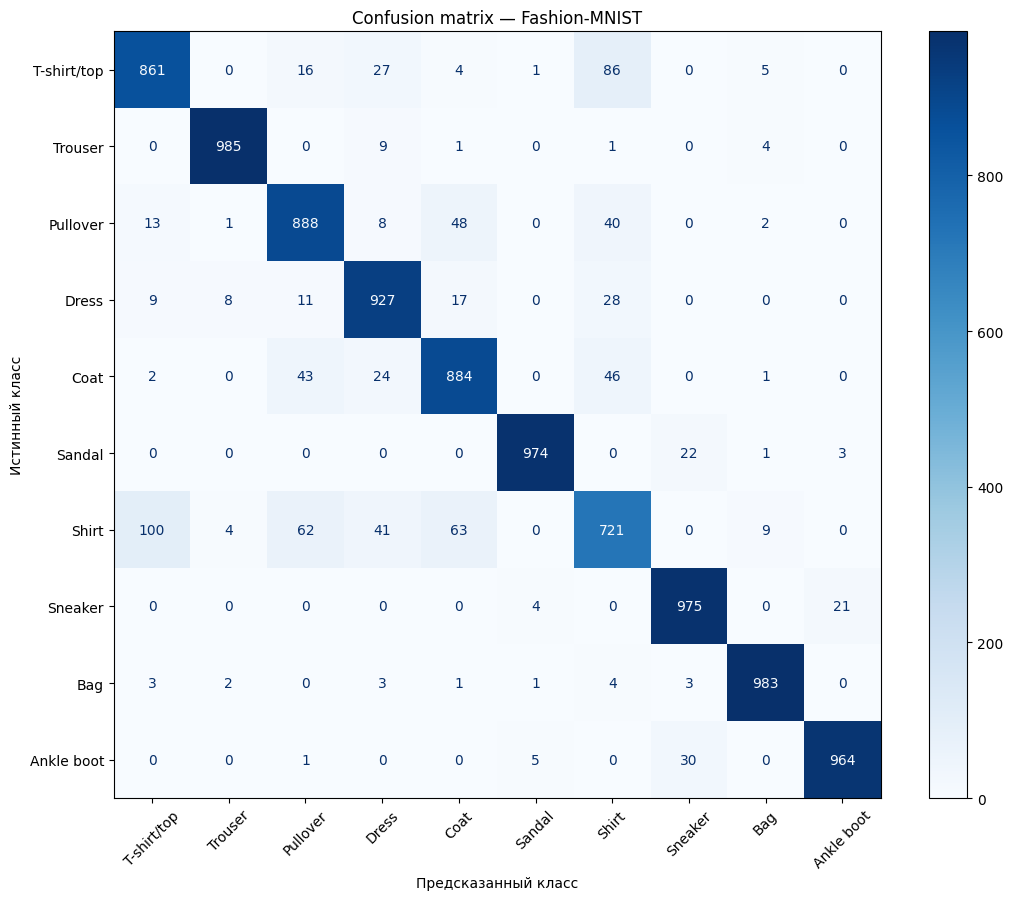

Изображение сохранено в: d:\Учеба\diplom_project\experiments\fashion_mnist\baseline\figures\confusion_matrix.png


In [48]:
from sklearn.metrics import ConfusionMatrixDisplay


figures_dir = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "figures"
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True,
)

confusion_png_path = (
    figures_dir
    / "confusion_matrix.png"
)

fig, ax = plt.subplots(
    figsize=(11, 9),
)

display = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=CLASS_NAMES,
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=True,
)

ax.set_title(
    "Confusion matrix — Fashion-MNIST"
)

ax.set_xlabel(
    "Предсказанный класс"
)

ax.set_ylabel(
    "Истинный класс"
)

fig.tight_layout()

fig.savefig(
    confusion_png_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print(
    "Изображение сохранено в:",
    confusion_png_path,
)

In [49]:
#Какой класс распознаётся лучше всего
class_accuracies = []

for class_id, class_name in enumerate(CLASS_NAMES):
    total_samples = confusion[class_id].sum()
    correct_predictions = confusion[
        class_id,
        class_id,
    ]

    accuracy = (
        correct_predictions / total_samples
    )

    class_accuracies.append(accuracy)

best_class_id = int(
    np.argmax(class_accuracies)
)

worst_class_id = int(
    np.argmin(class_accuracies)
)

print(
    "Лучше всего распознаётся:",
    CLASS_NAMES[best_class_id],
    class_accuracies[best_class_id],
)

print(
    "Хуже всего распознаётся:",
    CLASS_NAMES[worst_class_id],
    class_accuracies[worst_class_id],
)

Лучше всего распознаётся: Trouser 0.985
Хуже всего распознаётся: Shirt 0.721


In [50]:
#какие классы чаще всего путаются
pair_errors = []

num_classes = len(CLASS_NAMES)

for first_class in range(num_classes):
    for second_class in range(
        first_class + 1,
        num_classes,
    ):
        errors = (
            confusion[first_class, second_class]
            + confusion[second_class, first_class]
        )

        pair_errors.append(
            {
                "first_class": first_class,
                "second_class": second_class,
                "errors": int(errors),
            }
        )

most_confused_pair = max(
    pair_errors,
    key=lambda item: item["errors"],
)

first_class = most_confused_pair["first_class"]
second_class = most_confused_pair["second_class"]

print(
    "Чаще всего путаются:",
    CLASS_NAMES[first_class],
    "и",
    CLASS_NAMES[second_class],
)

print(
    "Количество ошибок в обе стороны:",
    most_confused_pair["errors"],
)

Чаще всего путаются: T-shirt/top и Shirt
Количество ошибок в обе стороны: 186


In [51]:
#Направление основной ошибки для каждого класса
for class_id, class_name in enumerate(CLASS_NAMES):
    errors = confusion[class_id].copy()

    # Убираем правильные предсказания
    errors[class_id] = 0

    most_common_wrong_class = int(
        np.argmax(errors)
    )

    print(
        f"{class_name} чаще всего принимает "
        f"за {CLASS_NAMES[most_common_wrong_class]}: "
        f"{errors[most_common_wrong_class]} раз"
    )

T-shirt/top чаще всего принимает за Shirt: 86 раз
Trouser чаще всего принимает за Dress: 9 раз
Pullover чаще всего принимает за Coat: 48 раз
Dress чаще всего принимает за Shirt: 28 раз
Coat чаще всего принимает за Shirt: 46 раз
Sandal чаще всего принимает за Sneaker: 22 раз
Shirt чаще всего принимает за T-shirt/top: 100 раз
Sneaker чаще всего принимает за Ankle boot: 21 раз
Bag чаще всего принимает за Shirt: 4 раз
Ankle boot чаще всего принимает за Sneaker: 30 раз


In [52]:
#Проверка симметричности ошибок
is_symmetric = np.array_equal(
    confusion,
    confusion.T,
)

print(
    "Матрица полностью симметрична:",
    is_symmetric,
)

Матрица полностью симметрична: False


In [53]:
max_difference = 0
most_asymmetric_pair = None

for first_class in range(num_classes):
    for second_class in range(
        first_class + 1,
        num_classes,
    ):
        difference = abs(
            confusion[first_class, second_class]
            - confusion[second_class, first_class]
        )

        if difference > max_difference:
            max_difference = difference
            most_asymmetric_pair = (
                first_class,
                second_class,
            )

first_class, second_class = most_asymmetric_pair

print(
    "Наиболее несимметричная пара:",
    CLASS_NAMES[first_class],
    "и",
    CLASS_NAMES[second_class],
)

print(
    f"{CLASS_NAMES[first_class]} → "
    f"{CLASS_NAMES[second_class]}:",
    confusion[first_class, second_class],
)

print(
    f"{CLASS_NAMES[second_class]} → "
    f"{CLASS_NAMES[first_class]}:",
    confusion[second_class, first_class],
)

Наиболее несимметричная пара: Pullover и Shirt
Pullover → Shirt: 40
Shirt → Pullover: 62


В рамках этапа 5.1 была подготовлена воспроизводимая базовая модель классификации изображений Fashion-MNIST. Исходная обучающая выборка была разделена на обучающую и валидационную части в соотношении 90:10, а тестовая выборка использовалась отдельно для итоговой оценки. Для обучения применялась CNN с 105 962 обучаемыми параметрами, оптимизатор Adam и функция потерь CrossEntropyLoss. Нормализация изображений выполнялась на основе среднего значения 0,2862 и стандартного отклонения 0,3532, рассчитанных только по обучающей выборке.

Лучшая модель была получена на 15-й эпохе. Точность на валидационной выборке составила 92,78%, а итоговая точность на тестовой выборке — 91,62%. Значение Macro-F1 составило 0,9156, что указывает на достаточно устойчивое качество классификации по совокупности классов. Наиболее точно распознавался класс Trouser — 98,5%, а наибольшие трудности возникали при распознавании класса Shirt — 72,1%. Основная группа ошибок была связана с различением классов T-shirt/top и Shirt; суммарно эти классы ошибочно принимались друг за друга 186 раз.

Таким образом, в результате этапа 5.1 сформирована и зафиксирована базовая линия эксперимента: сохранены параметры данных, архитектура CNN, настройки обучения, checkpoint лучшей модели, общие метрики и матрица ошибок. Полученная модель и результаты могут использоваться как контрольная точка для дальнейшего сравнения с моделями, обученными на дополненных синтетическими изображениями наборах данных.

### 16. Разделение train на F-A и F-B

In [54]:
from sklearn.model_selection import train_test_split


fa_experiment_root = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "fa_fb"
)

fa_experiment_root.mkdir(
    parents=True,
    exist_ok=True,
)

# Метки исходной полной обучающей выборки
full_targets = (
    full_train_dataset.targets
    .cpu()
    .numpy()
)

# F-A и F-B делим только внутри train
source_train_indices = np.asarray(
    train_indices,
    dtype=np.int64,
)

source_train_targets = full_targets[
    source_train_indices
]

fa_indices, fb_indices = train_test_split(
    source_train_indices,
    train_size=0.20,
    test_size=0.80,
    stratify=source_train_targets,
    random_state=SEED,
)

fa_indices = np.asarray(
    fa_indices,
    dtype=np.int64,
)

fb_indices = np.asarray(
    fb_indices,
    dtype=np.int64,
)

In [55]:
#Проверка размеров и пересечений
assert len(fa_indices) == 10800
assert len(fb_indices) == 43200

assert len(
    np.intersect1d(
        fa_indices,
        fb_indices,
    )
) == 0

combined_indices = np.concatenate(
    [fa_indices, fb_indices]
)

assert set(combined_indices) == set(
    source_train_indices
)

print("Размер F-A:", len(fa_indices))
print("Размер F-B:", len(fb_indices))
print("Размер validation:", len(validation_indices))
print("Размер test:", len(test_dataset))
print("F-A и F-B не пересекаются")

Размер F-A: 10800
Размер F-B: 43200
Размер validation: 6000
Размер test: 10000
F-A и F-B не пересекаются


In [56]:
#Проверка распределения классов
fa_class_counts = np.bincount(
    full_targets[fa_indices],
    minlength=len(CLASS_NAMES),
)

fb_class_counts = np.bincount(
    full_targets[fb_indices],
    minlength=len(CLASS_NAMES),
)

for class_id, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_id}: {class_name:12s} | "
        f"F-A = {fa_class_counts[class_id]:4d} | "
        f"F-B = {fb_class_counts[class_id]:4d}"
    )

0: T-shirt/top  | F-A = 1080 | F-B = 4320
1: Trouser      | F-A = 1080 | F-B = 4320
2: Pullover     | F-A = 1080 | F-B = 4320
3: Dress        | F-A = 1080 | F-B = 4320
4: Coat         | F-A = 1080 | F-B = 4320
5: Sandal       | F-A = 1080 | F-B = 4320
6: Shirt        | F-A = 1080 | F-B = 4320
7: Sneaker      | F-A = 1080 | F-B = 4320
8: Bag          | F-A = 1080 | F-B = 4320
9: Ankle boot   | F-A = 1080 | F-B = 4320


In [57]:
#Сохраним индексы
split_indices_path = (
    fa_experiment_root
    / "split_indices.npz"
)

np.savez(
    split_indices_path,
    fa_indices=fa_indices,
    fb_indices=fb_indices,
    validation_indices=validation_indices,
    test_indices=np.arange(
        len(test_dataset)
    ),
)

In [58]:
split_metadata = {
    "seed": int(SEED),
    "source_split": "original train split",
    "source_train_size": int(
        len(source_train_indices)
    ),
    "fa_size": int(len(fa_indices)),
    "fb_size": int(len(fb_indices)),
    "fa_fraction": 0.20,
    "fb_fraction": 0.80,
    "validation_size": int(
        len(validation_indices)
    ),
    "test_size": int(len(test_dataset)),
    "stratified": True,
}

split_metadata_path = (
    fa_experiment_root
    / "split_metadata.json"
)

split_metadata_path.write_text(
    json.dumps(
        split_metadata,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "Индексы сохранены в:",
    split_indices_path,
)

Индексы сохранены в: d:\Учеба\diplom_project\experiments\fashion_mnist\fa_fb\split_indices.npz


### 17. Подготовка датасетов для F-A

In [59]:
#Для нового эксперимента посчитаем нормализацию только по F-A
from copy import copy
from torch.utils.data import Subset


fa_mean, fa_std = calculate_train_mean_std(
    full_train_dataset=full_train_dataset,
    train_indices=fa_indices,
)

print("Среднее F-A:", fa_mean)
print("Стандартное отклонение F-A:", fa_std)

Среднее F-A: 0.28624583872177345
Стандартное отклонение F-A: 0.3536617571752594


In [60]:
#Создадим отдельные копии датасетов, чтобы не менять предыдущий эксперимент
fa_transform = create_normalized_transform(
    mean=fa_mean,
    std=fa_std,
)

fa_parent_dataset = copy(
    full_train_dataset
)

fa_parent_dataset.transform = fa_transform

fa_test_parent_dataset = copy(
    test_dataset
)

fa_test_parent_dataset.transform = fa_transform

In [61]:
#Создадим F-A, F-B и validation
fa_dataset = Subset(
    fa_parent_dataset,
    fa_indices.tolist(),
)

fb_dataset = Subset(
    fa_parent_dataset,
    fb_indices.tolist(),
)

fa_validation_dataset = Subset(
    fa_parent_dataset,
    validation_indices.tolist(),
)

fa_test_dataset = fa_test_parent_dataset

In [62]:
#Проверим размеры
print("F-A:", len(fa_dataset))
print("F-B:", len(fb_dataset))
print(
    "Validation:",
    len(fa_validation_dataset),
)
print("Test:", len(fa_test_dataset))

F-A: 10800
F-B: 43200
Validation: 6000
Test: 10000


### 18. Обучение CNN только на F-A

In [63]:
from torch.utils.data import DataLoader


fa_train_loader = DataLoader(
    fa_dataset,
    batch_size=training_config["batch_size"],
    shuffle=True,
    num_workers=0,
)

fa_validation_loader = DataLoader(
    fa_validation_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)

fa_test_loader = DataLoader(
    fa_test_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)

print(
    "Train batches:",
    len(fa_train_loader),
)

print(
    "Validation batches:",
    len(fa_validation_loader),
)

print(
    "Test batches:",
    len(fa_test_loader),
)

Train batches: 85
Validation batches: 47
Test batches: 79


In [64]:
#Создадим отдельную конфигурацию
fa_training_config = {
    **training_config,
    "train_split": "F-A",
    "train_size": len(fa_dataset),
    "validation_size": len(
        fa_validation_dataset
    ),
    "test_size": len(fa_test_dataset),
}

In [65]:
#Пути для нового эксперимента
fa_baseline_root = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "fa_baseline"
)

fa_checkpoint_path = (
    fa_baseline_root
    / "checkpoints"
    / "best_model.pt"
)

fa_history_path = (
    fa_baseline_root
    / "history.json"
)

In [66]:
#Метаданные нового checkpoint
fa_normalization_config = {
    "mean": float(fa_mean),
    "std": float(fa_std),
    "calculated_from": "F-A only",
}

fa_checkpoint_metadata = {
    "experiment": "F-A baseline",
    "seed": int(SEED),
    "normalization": fa_normalization_config,
    "architecture": architecture_config,
    "training": fa_training_config,
    "dataset_sizes": {
        "train": len(fa_dataset),
        "validation": len(
            fa_validation_dataset
        ),
        "test": len(fa_test_dataset),
        "fb_reserved": len(fb_dataset),
    },
}

In [67]:
#Создадим CNN с нуля
set_seed(SEED)

fa_model = FashionCNN(
    dropout=fa_training_config["dropout"]
).to(device)

fa_criterion = nn.CrossEntropyLoss()

fa_optimizer = torch.optim.Adam(
    fa_model.parameters(),
    lr=fa_training_config[
        "learning_rate"
    ],
    weight_decay=fa_training_config[
        "weight_decay"
    ],
)

In [68]:
#Запустим обучение
from src.train import fit


fa_history = fit(
    model=fa_model,
    train_loader=fa_train_loader,
    validation_loader=fa_validation_loader,
    criterion=fa_criterion,
    optimizer=fa_optimizer,
    device=device,
    epochs=fa_training_config["epochs"],
    checkpoint_path=fa_checkpoint_path,
    history_path=fa_history_path,
    checkpoint_metadata=(
        fa_checkpoint_metadata
    ),
)

Epoch 01/15 | train loss: 0.8318 | train accuracy: 0.7125 | validation loss: 0.4783 | validation accuracy: 0.8353
Epoch 02/15 | train loss: 0.4762 | train accuracy: 0.8309 | validation loss: 0.4086 | validation accuracy: 0.8545
Epoch 03/15 | train loss: 0.4151 | train accuracy: 0.8551 | validation loss: 0.3487 | validation accuracy: 0.8773
Epoch 04/15 | train loss: 0.3672 | train accuracy: 0.8700 | validation loss: 0.3434 | validation accuracy: 0.8782
Epoch 05/15 | train loss: 0.3269 | train accuracy: 0.8853 | validation loss: 0.3175 | validation accuracy: 0.8852
Epoch 06/15 | train loss: 0.2984 | train accuracy: 0.8941 | validation loss: 0.3168 | validation accuracy: 0.8845
Epoch 07/15 | train loss: 0.2812 | train accuracy: 0.8966 | validation loss: 0.2993 | validation accuracy: 0.8902
Epoch 08/15 | train loss: 0.2593 | train accuracy: 0.9077 | validation loss: 0.2881 | validation accuracy: 0.8953
Epoch 09/15 | train loss: 0.2386 | train accuracy: 0.9122 | validation loss: 0.2914 | va

### 19. Итоговая оценка F-A модели

In [69]:
#Загрузим лучший checkpoint
fa_checkpoint = torch.load(
    fa_checkpoint_path,
    map_location=device,
)

fa_best_model = FashionCNN(
    dropout=fa_training_config["dropout"]
).to(device)

fa_best_model.load_state_dict(
    fa_checkpoint["model_state_dict"]
)

fa_best_model.eval()

print(
    "Лучшая эпоха:",
    fa_checkpoint["epoch"],
)

print(
    "Validation accuracy:",
    fa_checkpoint[
        "validation_accuracy"
    ],
)

Лучшая эпоха: 14
Validation accuracy: 0.9013333333333333


In [70]:
#Получим предсказания на test
fa_all_labels = []
fa_all_predictions = []

with torch.no_grad():
    for images, labels in fa_test_loader:
        images = images.to(device)

        logits = fa_best_model(images)

        predictions = logits.argmax(
            dim=1
        )

        fa_all_labels.append(
            labels.cpu()
        )

        fa_all_predictions.append(
            predictions.cpu()
        )

fa_y_true = torch.cat(
    fa_all_labels
).numpy()

fa_y_pred = torch.cat(
    fa_all_predictions
).numpy()

print(
    "Количество test-изображений:",
    len(fa_y_true),
)

Количество test-изображений: 10000


In [71]:
#Рассчитаем общие метрики
from sklearn.metrics import (
    accuracy_score,
    f1_score,
)


fa_test_accuracy = accuracy_score(
    fa_y_true,
    fa_y_pred,
)

fa_macro_f1 = f1_score(
    fa_y_true,
    fa_y_pred,
    average="macro",
    zero_division=0,
)

print(
    "F-A test accuracy:",
    fa_test_accuracy,
)

print(
    "F-A test accuracy (%):",
    fa_test_accuracy * 100,
)

print(
    "F-A Macro-F1:",
    fa_macro_f1,
)

F-A test accuracy: 0.8885
F-A test accuracy (%): 88.85
F-A Macro-F1: 0.8879213721519973


In [72]:
#Рассчитаем accuracy по классам
from sklearn.metrics import confusion_matrix


fa_class_ids = np.arange(
    len(CLASS_NAMES)
)

fa_confusion = confusion_matrix(
    fa_y_true,
    fa_y_pred,
    labels=fa_class_ids,
)

fa_per_class_metrics = []

for class_id, class_name in enumerate(
    CLASS_NAMES
):
    total_samples = fa_confusion[
        class_id
    ].sum()

    correct_predictions = fa_confusion[
        class_id,
        class_id,
    ]

    class_accuracy = (
        correct_predictions
        / total_samples
    )

    fa_per_class_metrics.append(
        {
            "class_id": int(class_id),
            "class_name": class_name,
            "total_samples": int(
                total_samples
            ),
            "correct_predictions": int(
                correct_predictions
            ),
            "accuracy": float(
                class_accuracy
            ),
        }
    )

    print(
        f"{class_id} — {class_name}: "
        f"{class_accuracy:.4f}"
    )

0 — T-shirt/top: 0.8330
1 — Trouser: 0.9760
2 — Pullover: 0.8050
3 — Dress: 0.8980
4 — Coat: 0.8690
5 — Sandal: 0.9590
6 — Shirt: 0.6540
7 — Sneaker: 0.9590
8 — Bag: 0.9680
9 — Ankle boot: 0.9640


In [73]:
#Сохраним результаты
import csv


fa_metrics_dir = (
    fa_baseline_root
    / "metrics"
)

fa_figures_dir = (
    fa_baseline_root
    / "figures"
)

fa_metrics_dir.mkdir(
    parents=True,
    exist_ok=True,
)

fa_figures_dir.mkdir(
    parents=True,
    exist_ok=True,
)

In [74]:
fa_test_metrics = {
    "experiment": "F-A baseline",
    "train_size": len(fa_dataset),
    "validation_size": len(
        fa_validation_dataset
    ),
    "test_size": len(fa_test_dataset),
    "checkpoint_epoch": int(
        fa_checkpoint["epoch"]
    ),
    "validation_accuracy": float(
        fa_checkpoint[
            "validation_accuracy"
        ]
    ),
    "test_accuracy": float(
        fa_test_accuracy
    ),
    "macro_f1": float(
        fa_macro_f1
    ),
    "seed": int(SEED),
}

fa_test_metrics_path = (
    fa_metrics_dir
    / "test_metrics.json"
)

fa_test_metrics_path.write_text(
    json.dumps(
        fa_test_metrics,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

252

In [75]:
fa_per_class_path = (
    fa_metrics_dir
    / "per_class_metrics.csv"
)

with fa_per_class_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:

    fieldnames = [
        "class_id",
        "class_name",
        "total_samples",
        "correct_predictions",
        "accuracy",
    ]

    writer = csv.DictWriter(
        csv_file,
        fieldnames=fieldnames,
    )

    writer.writeheader()
    writer.writerows(
        fa_per_class_metrics
    )

In [76]:
#Сохраним confusion matrix
fa_confusion_path = (
    fa_metrics_dir
    / "confusion_matrix.csv"
)

with fa_confusion_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:

    writer = csv.writer(csv_file)

    writer.writerow(
        ["true_class"] + list(CLASS_NAMES)
    )

    for class_name, row in zip(
        CLASS_NAMES,
        fa_confusion,
    ):
        writer.writerow(
            [class_name] + row.tolist()
        )

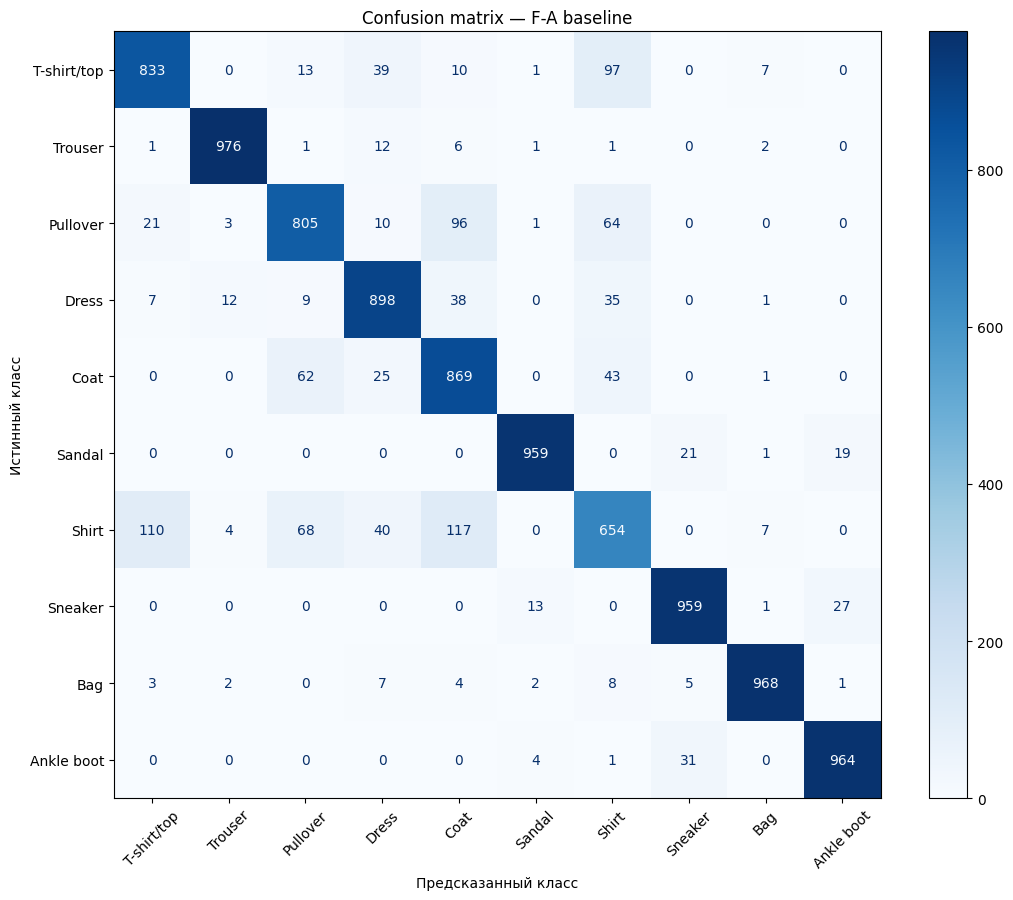

In [77]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
)


fa_confusion_figure_path = (
    fa_figures_dir
    / "confusion_matrix.png"
)

fig, ax = plt.subplots(
    figsize=(11, 9),
)

display = ConfusionMatrixDisplay(
    confusion_matrix=fa_confusion,
    display_labels=CLASS_NAMES,
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
)

ax.set_title(
    "Confusion matrix — F-A baseline"
)

ax.set_xlabel(
    "Предсказанный класс"
)

ax.set_ylabel(
    "Истинный класс"
)

fig.tight_layout()

fig.savefig(
    fa_confusion_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

В рамках этапа была сформирована базовая модель F-A для экспериментов с ограниченным количеством реальных обучающих данных. Исходная обучающая выборка из 54 000 изображений была случайным образом и стратифицированно разделена с фиксированным seed, равным 42, на F-A и F-B. Набор F-A содержит 10 800 изображений, то есть 20% исходной обучающей выборки, а набор F-B — 43 200 изображений. В каждом классе F-A содержит по 1 080 изображений, а F-B — по 4 320. Validation и test-выборки оставались неизменными.

На наборе F-A была обучена та же CNN-архитектура, содержащая 105 962 обучаемых параметра. Для обучения использовались оптимизатор Adam, функция потерь CrossEntropyLoss и те же основные параметры обучения, что и для исходной baseline-модели. Нормализация была рассчитана только по F-A: среднее значение составило 0,28625, стандартное отклонение — 0,35366.

Лучшая модель была получена на 14-й эпохе. Её validation accuracy составила 90,13%, итоговая test accuracy — 88,85%, а Macro-F1 — 0,8879. Наиболее точно распознавался класс Trouser — 97,6%, а хуже всего — Shirt — 65,4%. Наиболее часто модель путала классы T-shirt/top и Shirt: суммарно было зафиксировано 207 ошибок в обоих направлениях.

По сравнению с моделью, обученной на полной обучающей выборке, точность на test снизилась с 91,62% до 88,85%, то есть на 2,77 процентного пункта. Это показывает влияние сокращения объёма обучающих данных на качество классификации. Полученная F-A-модель и её метрики зафиксированы как новая базовая точка для последующего эксперимента с добавлением данных из F-B.